# Computer Vision (AI4002) — Semester Project Part 2
## Hybrid Feature Learning: Integration of Handcrafted and Deep Features for Pancreas CT Segmentation

| Field | Details |
| :--- | :--- |
| **Group No.** | Group 18 |
| **Student 1** | Syed Muhammad Raza (`23F-0040`) — **Model:** `AttentionResUNet` \| **Extractors:** Dense LBP, Gabor Filter Bank |
| **Student 2** | Muhammad Ahmad (`23F-0022`) — **Model:** `TransUNet-Lite` \| **Extractors:** Dense Spatial HOG, Multi-Scale LoG |
| **Base Paper** | Qiu *et al.* (2024), *Multi-scale U-Net with attention mechanism for pancreas segmentation*, Frontiers in Oncology (SJR Q1) |
| **Dataset** | Medical Segmentation Decathlon (MSD) Task07 Pancreas (8,792 axial slices, 256×256, HU window [-100, +240]) |
| **Cloud Infrastructure** | Modal Serverless NVIDIA A10G GPUs + Hugging Face Hub (`razaasherazi/pancreas-multiscale-unet-baseline`) |

## 1. Environment & Experimental Consistency Protocol
To ensure a strictly fair ablation across all 6 experimental runs, all training hyperparameters are locked:
- **Epochs:** 30 | **Batch Size:** 32 | **Precision:** IEEE-754 FP32 (TF32 disabled)
- **Optimizer:** AdamW (`lr=1e-4`, `weight_decay=1e-5`) with `CosineAnnealingLR`
- **Loss Function:** Composite `DiceBCELoss` (0.5 Dice + 0.5 FP32-clamped BCE)
- **Augmentation:** Synchronous random horizontal/vertical flips and $\pm 8^\circ$ affine rotations

## 2. Dense Spatial Handcrafted Feature Extractors (`src/handcrafted.py`)
Implements four GPU-vectorized, per-slice Z-score normalized spatial extractors (`LBP`, `Gabor`, `Dense HOG`, `Multi-Scale LoG`) outputting $256 \times 256$ pixel-aligned feature maps:

```python
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class DenseHandcraftedExtractor(nn.Module):
    """
    GPU-accelerated, FP32-enforced dense spatial handcrafted feature extractors.
    Outputs pixel-aligned (B, C, H, W) feature maps normalized per slice.
    """

    def __init__(self, mode: str = "none"):
        super().__init__()
        self.mode = mode.lower()
        assert self.mode in {"none", "lbp", "gabor", "hog", "log"}, f"Unsupported mode: {mode}"

        if self.mode == "lbp":
            self.out_channels = 1
            offsets = [
                (-1, -1), (-1, 0), (-1, 1),
                (0, 1), (1, 1), (1, 0),
                (1, -1), (0, -1)
            ]
            kernels = torch.zeros((8, 1, 3, 3), dtype=torch.float32)
            for idx, (dy, dx) in enumerate(offsets):
                kernels[idx, 0, 1 + dy, 1 + dx] = 1.0
                kernels[idx, 0, 1, 1] = -1.0
            weights = torch.tensor([2 ** i for i in range(8)], dtype=torch.float32).view(1, 8, 1, 1)
            self.register_buffer("lbp_kernels", kernels)
            self.register_buffer("lbp_weights", weights)

        elif self.mode == "gabor":
            self.out_channels = 4
            kernels = self._build_gabor_bank(
                ksize=9,
                sigma=2.0,
                lambd=5.0,
                gamma=0.5,
                thetas=[0.0, math.pi / 4, math.pi / 2, 3 * math.pi / 4]
            )
            self.register_buffer("gabor_kernels", kernels)

        elif self.mode == "hog":
            self.out_channels = 4
            sobel_x = torch.tensor([[-1.0, 0.0, 1.0],
                                    [-2.0, 0.0, 2.0],
                                    [-1.0, 0.0, 1.0]], dtype=torch.float32).view(1, 1, 3, 3)
            sobel_y = torch.tensor([[-1.0, -2.0, -1.0],
                                    [0.0,  0.0,  0.0],
                                    [1.0,  2.0,  1.0]], dtype=torch.float32).view(1, 1, 3, 3)
            self.register_buffer("sobel_x", sobel_x)
            self.register_buffer("sobel_y", sobel_y)

        elif self.mode == "log":
            self.out_channels = 3
            sigmas = [1.0, 2.0, 4.0]
            self.sigmas = sigmas
            for idx, s in enumerate(sigmas):
                k = self._build_log_kernel(sigma=s)
                self.register_buffer(f"log_kernel_{idx}", k)

        else:
            self.out_channels = 0

    @staticmethod
    def _build_gabor_bank(ksize: int, sigma: float, lambd: float, gamma: float, thetas: list):
        half = ksize // 2
        y, x = torch.meshgrid(
            torch.arange(-half, half + 1, dtype=torch.float32),
            torch.arange(-half, half + 1, dtype=torch.float32),
            indexing="ij"
        )
        filters = []
        for theta in thetas:
            x_theta = x * math.cos(theta) + y * math.sin(theta)
            y_theta = -x * math.sin(theta) + y * math.cos(theta)
            gb = torch.exp(-0.5 * (x_theta ** 2 + (gamma ** 2) * (y_theta ** 2)) / (sigma ** 2))
            gb = gb * torch.cos(2.0 * math.pi * x_theta / lambd)
            gb = gb - gb.mean()
            gb = gb / (gb.norm() + 1e-6)
            filters.append(gb.view(1, 1, ksize, ksize))
        return torch.cat(filters, dim=0)

    @staticmethod
    def _build_log_kernel(sigma: float):
        ksize = int(2 * math.ceil(3 * sigma) + 1)
        half = ksize // 2
        y, x = torch.meshgrid(
            torch.arange(-half, half + 1, dtype=torch.float32),
            torch.arange(-half, half + 1, dtype=torch.float32),
            indexing="ij"
        )
        r2 = x ** 2 + y ** 2
        sigma2 = sigma ** 2
        norm = -1.0 / (math.pi * (sigma2 ** 2))
        log_k = norm * (1.0 - r2 / (2.0 * sigma2)) * torch.exp(-r2 / (2.0 * sigma2))
        log_k = log_k - log_k.mean()
        log_k = log_k * sigma2
        return log_k.view(1, 1, ksize, ksize)

    @staticmethod
    def _normalize_per_slice(feat: torch.Tensor) -> torch.Tensor:
        feat = feat.float()
        mean = feat.mean(dim=(2, 3), keepdim=True)
        std = torch.clamp(feat.std(dim=(2, 3), keepdim=True), min=1e-5)
        return (feat - mean) / std

    def forward(self, x: torch.Tensor):
        if self.mode == "none":
            return None

        x = x.float()

        if self.mode == "lbp":
            diff = F.conv2d(x, self.lbp_kernels, padding=1)
            bits = (diff >= 0).float()
            lbp_map = (bits * self.lbp_weights).sum(dim=1, keepdim=True) / 255.0
            return self._normalize_per_slice(lbp_map)

        if self.mode == "gabor":
            pad = self.gabor_kernels.shape[-1] // 2
            resp = torch.abs(F.conv2d(x, self.gabor_kernels, padding=pad))
            return self._normalize_per_slice(resp)

        if self.mode == "hog":
            gx = F.conv2d(x, self.sobel_x, padding=1)
            gy = F.conv2d(x, self.sobel_y, padding=1)
            mag = torch.sqrt(gx ** 2 + gy ** 2 + 1e-6)
            c0 = torch.abs(gx)
            c45 = torch.abs(gx + gy) / math.sqrt(2.0)
            c90 = torch.abs(gy)
            c135 = torch.abs(gx - gy) / math.sqrt(2.0)
            hog_raw = torch.cat([c0, c45, c90, c135], dim=1)
            hog_smooth = F.avg_pool2d(hog_raw, kernel_size=5, stride=1, padding=2)
            hog_norm = hog_smooth / (mag + 1e-4)
            return self._normalize_per_slice(hog_norm)

        if self.mode == "log":
            outputs = []
            for idx in range(len(self.sigmas)):
                k = getattr(self, f"log_kernel_{idx}")
                pad = k.shape[-1] // 2
                outputs.append(F.conv2d(x, k, padding=pad))
            log_map = torch.cat(outputs, dim=1)
            return self._normalize_per_slice(log_map)
```

## 3. Student 1 Architecture: Attention Residual U-Net + SE Attention Fusion (`src/models/att_resunet.py`)
Integrates Residual Convolutional Blocks, Skip-Connection Attention Gates, and Squeeze-and-Excitation (SE) Channel Attention Fusion across Encoder Stages 1 and 2:

```python
import torch
import torch.nn as nn
import torch.nn.functional as F
from src.handcrafted import DenseHandcraftedExtractor


class ResidualConvBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.shortcut = (
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_ch),
            )
            if in_ch != out_ch
            else nn.Identity()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.conv(x) + self.shortcut(x))


class AttentionGate(nn.Module):
    """Suppresses background retroperitoneal fat responses on skip connections."""
    def __init__(self, F_g: int, F_l: int, F_int: int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        psi = self.relu(self.W_g(g) + self.W_x(x))
        alpha = self.psi(psi)
        return x * alpha


class SEAttentionFusion(nn.Module):
    """
    Squeeze-and-Excitation (SE) Attention-Based Feature Fusion:
    Projects handcrafted maps, concatenates with deep encoder features,
    and dynamically recalibrates channel importance.
    """
    def __init__(self, deep_ch: int, hc_ch: int, reduction: int = 8):
        super().__init__()
        self.hc_stem = nn.Sequential(
            nn.Conv2d(hc_ch, deep_ch // 2, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(deep_ch // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(deep_ch // 2, deep_ch // 2, kernel_size=1, bias=False),
            nn.BatchNorm2d(deep_ch // 2),
            nn.ReLU(inplace=True),
        )
        total_ch = deep_ch + (deep_ch // 2)
        self.se_fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(total_ch, total_ch // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(total_ch // reduction, total_ch, bias=False),
            nn.Sigmoid(),
        )
        self.out_proj = nn.Sequential(
            nn.Conv2d(total_ch, deep_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(deep_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, deep_feat, hc_feat):
        hc_proj = self.hc_stem(hc_feat)
        fused = torch.cat([deep_feat, hc_proj], dim=1)
        weights = self.se_fc(fused).unsqueeze(-1).unsqueeze(-1)
        recalibrated = fused * weights
        return self.out_proj(recalibrated)


class AttentionResUNet(nn.Module):
    """
    Student 1 Advanced Architecture: Attention Residual U-Net
    Supports feature_mode in {'none', 'lbp', 'gabor'}.
    """
    def __init__(self, in_channels: int = 1, out_channels: int = 1, feature_mode: str = "none"):
        super().__init__()
        self.feature_mode = feature_mode.lower()
        self.extractor = DenseHandcraftedExtractor(mode=self.feature_mode)
        self.use_fusion = self.extractor.out_channels > 0

        filters = [32, 64, 128, 256, 512]

        # Encoder
        self.enc1 = ResidualConvBlock(in_channels, filters[0])
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ResidualConvBlock(filters[0], filters[1])
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ResidualConvBlock(filters[1], filters[2])
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = ResidualConvBlock(filters[2], filters[3])
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = ResidualConvBlock(filters[3], filters[4])

        # Multi-scale SE Attention Fusion at Stage 1 & Stage 2
        if self.use_fusion:
            hc_c = self.extractor.out_channels
            self.fuse1 = SEAttentionFusion(deep_ch=filters[0], hc_ch=hc_c)
            self.fuse2 = SEAttentionFusion(deep_ch=filters[1], hc_ch=hc_c)

        # Decoder with Attention Gates
        self.up4 = nn.ConvTranspose2d(filters[4], filters[3], kernel_size=2, stride=2)
        self.att4 = AttentionGate(F_g=filters[3], F_l=filters[3], F_int=filters[2])
        self.dec4 = ResidualConvBlock(filters[4], filters[3])

        self.up3 = nn.ConvTranspose2d(filters[3], filters[2], kernel_size=2, stride=2)
        self.att3 = AttentionGate(F_g=filters[2], F_l=filters[2], F_int=filters[1])
        self.dec3 = ResidualConvBlock(filters[3], filters[2])

        self.up2 = nn.ConvTranspose2d(filters[2], filters[1], kernel_size=2, stride=2)
        self.att2 = AttentionGate(F_g=filters[1], F_l=filters[1], F_int=filters[0])
        self.dec2 = ResidualConvBlock(filters[2], filters[1])

        self.up1 = nn.ConvTranspose2d(filters[1], filters[0], kernel_size=2, stride=2)
        self.att1 = AttentionGate(F_g=filters[0], F_l=filters[0], F_int=16)
        self.dec1 = ResidualConvBlock(filters[1], filters[0])

        self.final_conv = nn.Conv2d(filters[0], out_channels, kernel_size=1)

    def forward(self, x):
        hc_map = self.extractor(x) if self.use_fusion else None

        e1 = self.enc1(x)
        if self.use_fusion:
            e1 = self.fuse1(e1, hc_map)

        e2 = self.enc2(self.pool1(e1))
        if self.use_fusion:
            hc_half = F.avg_pool2d(hc_map, kernel_size=2, stride=2)
            e2 = self.fuse2(e2, hc_half)

        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        e4_att = self.att4(g=d4, x=e4)
        d4 = self.dec4(torch.cat([e4_att, d4], dim=1))

        d3 = self.up3(d4)
        e3_att = self.att3(g=d3, x=e3)
        d3 = self.dec3(torch.cat([e3_att, d3], dim=1))

        d2 = self.up2(d3)
        e2_att = self.att2(g=d2, x=e2)
        d2 = self.dec2(torch.cat([e2_att, d2], dim=1))

        d1 = self.up1(d2)
        e1_att = self.att1(g=d1, x=e1)
        d1 = self.dec1(torch.cat([e1_att, d1], dim=1))

        return torch.sigmoid(self.final_conv(d1))
```

## 4. Student 2 Architecture: Hybrid CNN-Transformer + Projection Concatenation Fusion (`src/models/transunet_lite.py`)
Combines a 4-stage CNN encoder with a 3-layer Multi-Head Self-Attention (MHSA) Transformer Bottleneck ($16 \times 16$ spatial tokens) and $1\times1$ Projection + Channel Concatenation Fusion:

```python
import torch
import torch.nn as nn
import torch.nn.functional as F
from src.handcrafted import DenseHandcraftedExtractor


class ConvBNReLU(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
        )

    def forward(self, x):
        return self.block(x)


class ProjectionConcatFusion(nn.Module):
    """
    Projection & Dimensionality Alignment followed by Channel Concatenation Fusion:
    Aligns dense handcrafted features via 1x1 projection and fuses with CNN encoder features.
    """
    def __init__(self, deep_ch: int, hc_ch: int):
        super().__init__()
        proj_ch = deep_ch // 2
        self.hc_proj = nn.Sequential(
            nn.Conv2d(hc_ch, proj_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(proj_ch),
            nn.GELU(),
        )
        self.fusion_conv = nn.Sequential(
            nn.Conv2d(deep_ch + proj_ch, deep_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(deep_ch),
            nn.GELU(),
        )

    def forward(self, deep_feat, hc_feat):
        hc_aligned = self.hc_proj(hc_feat)
        concat = torch.cat([deep_feat, hc_aligned], dim=1)
        return self.fusion_conv(concat)


class TransformerBottleneck(nn.Module):
    """
    2D Spatial Vision Transformer Bottleneck:
    Models global long-range dependencies across abdominal organs at 16x16 resolution.
    """
    def __init__(self, embed_dim: int = 256, num_heads: int = 8, num_layers: int = 3, grid_size: int = 16):
        super().__init__()
        num_tokens = grid_size * grid_size
        self.pos_embed = nn.Parameter(torch.zeros(1, num_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):
        B, C, H, W = x.shape
        tokens = x.flatten(2).transpose(1, 2)  # (B, H*W, C)
        tokens = tokens + self.pos_embed
        out_tokens = self.transformer(tokens)
        return out_tokens.transpose(1, 2).reshape(B, C, H, W)


class TransUNetLite(nn.Module):
    """
    Student 2 Advanced Architecture: Hybrid CNN-Transformer Segmentation Network
    Supports feature_mode in {'none', 'hog', 'log'}.
    """
    def __init__(self, in_channels: int = 1, out_channels: int = 1, feature_mode: str = "none"):
        super().__init__()
        self.feature_mode = feature_mode.lower()
        self.extractor = DenseHandcraftedExtractor(mode=self.feature_mode)
        self.use_fusion = self.extractor.out_channels > 0

        dims = [32, 64, 128, 256]

        # CNN Encoder (256 -> 128 -> 64 -> 32 -> 16)
        self.enc1 = ConvBNReLU(in_channels, dims[0])
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBNReLU(dims[0], dims[1])
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ConvBNReLU(dims[1], dims[2])
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = ConvBNReLU(dims[2], dims[3])
        self.pool4 = nn.MaxPool2d(2)

        if self.use_fusion:
            hc_c = self.extractor.out_channels
            self.fuse1 = ProjectionConcatFusion(deep_ch=dims[0], hc_ch=hc_c)
            self.fuse3 = ProjectionConcatFusion(deep_ch=dims[2], hc_ch=hc_c)

        # Global Self-Attention Bottleneck at 16x16
        self.vit_bottleneck = TransformerBottleneck(embed_dim=dims[3], num_heads=8, num_layers=3, grid_size=16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(dims[3], dims[3], kernel_size=2, stride=2)
        self.dec4 = ConvBNReLU(dims[3] + dims[3], dims[2])

        self.up3 = nn.ConvTranspose2d(dims[2], dims[2], kernel_size=2, stride=2)
        self.dec3 = ConvBNReLU(dims[2] + dims[2], dims[1])

        self.up2 = nn.ConvTranspose2d(dims[1], dims[1], kernel_size=2, stride=2)
        self.dec2 = ConvBNReLU(dims[1] + dims[1], dims[0])

        self.up1 = nn.ConvTranspose2d(dims[0], dims[0], kernel_size=2, stride=2)
        self.dec1 = ConvBNReLU(dims[0] + dims[0], dims[0])

        self.head = nn.Conv2d(dims[0], out_channels, kernel_size=1)

    def forward(self, x):
        hc_map = self.extractor(x) if self.use_fusion else None

        e1 = self.enc1(x)
        if self.use_fusion:
            e1 = self.fuse1(e1, hc_map)

        e2 = self.enc2(self.pool1(e1))

        e3 = self.enc3(self.pool2(e2))
        if self.use_fusion:
            hc_quarter = F.avg_pool2d(hc_map, kernel_size=4, stride=4)
            e3 = self.fuse3(e3, hc_quarter)

        e4 = self.enc4(self.pool3(e3))
        b = self.vit_bottleneck(self.pool4(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return torch.sigmoid(self.head(d1))
```

## 5. FP32-Safe Composite Loss & Modal Cloud Training Pipeline (`src/utils/loss.py` & `modal_app_part2.py`)

```python
import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceBCELoss(nn.Module):
    """
    FP32-safe composite Dice + Binary Cross-Entropy Loss for A10G / Ampere GPUs.
    """
    def __init__(self, dice_weight: float = 0.5, bce_weight: float = 0.5, smooth: float = 1e-6):
        super().__init__()
        self.dice_weight = dice_weight
        self.bce_weight = bce_weight
        self.smooth = smooth

    def forward(self, preds: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        preds = preds.float().contiguous()
        targets = targets.float().contiguous()

        intersection = (preds * targets).sum(dim=(2, 3))
        union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = 1.0 - (2.0 * intersection + self.smooth) / (union + self.smooth)

        preds_clamped = torch.clamp(preds, min=1e-6, max=1.0 - 1e-6)
        bce_loss = F.binary_cross_entropy(preds_clamped, targets, reduction="mean")

        return (self.dice_weight * dice_loss.mean()) + (self.bce_weight * bce_loss)


class FocalTverskyLoss(nn.Module):
    def __init__(self, alpha=0.6, beta=0.4, gamma=1.33, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, preds, targets):
        preds = preds.contiguous()
        targets = targets.contiguous()

        tp = (preds * targets).sum(dim=(2, 3))
        fp = (preds * (1.0 - targets)).sum(dim=(2, 3))
        fn = ((1.0 - preds) * targets).sum(dim=(2, 3))

        tversky_index = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        focal_tversky = torch.pow((1.0 - tversky_index), 1.0 / self.gamma)
        return focal_tversky.mean()


class HybridTverskyBCELoss(nn.Module):
    """
    Experiment 3: Composite loss balancing point-wise cross-entropy stability
    with asymmetric boundary penalization.
    - alpha=0.7: heavier penalty on False Positives to halt boundary leakage
    - beta=0.3:  maintains sensitivity to genuine lesion tissue
    - bce_weight=0.5: provides smooth convex gradient anchor across background
    - tversky_weight=0.5: drives structural boundary convergence
    """
    def __init__(self, alpha=0.7, beta=0.3, bce_weight=0.5, tversky_weight=0.5, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.bce_weight = bce_weight
        self.tversky_weight = tversky_weight
        self.smooth = smooth

    def forward(self, preds, targets):
        preds = preds.contiguous()
        targets = targets.contiguous()

        # 1. Point-wise BCE Loss (Anchor for background stability)
        bce = F.binary_cross_entropy(preds, targets, reduction='mean')

        # 2. Asymmetric Tversky Loss
        tp = (preds * targets).sum(dim=(2, 3))
        fp = (preds * (1.0 - targets)).sum(dim=(2, 3))
        fn = ((1.0 - preds) * targets).sum(dim=(2, 3))

        tversky_index = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        tversky_loss = 1.0 - tversky_index

        return (self.bce_weight * bce) + (self.tversky_weight * tversky_loss.mean())
    
```

```python
import os
from pathlib import Path
import modal

HF_REPO_ID = "razaasherazi/pancreas-multiscale-unet-baseline"

app = modal.App("pancreas-part2-hybrid-runner")
volume = modal.Volume.from_name("pancreas-data-vol", create_if_missing=True)

image = (
    modal.Image.debian_slim(python_version="3.11")
    .pip_install(
        "torch",
        "torchvision",
        "opencv-python-headless",
        "numpy",
        "matplotlib",
        "tqdm",
        "huggingface_hub",
    )
    .add_local_dir(str(Path(__file__).parent / "src"), remote_path="/root/src")
)

RUN_CONFIGS = {
    1: {
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run1_att_resunet_base",
        "arch": "att_resunet",
        "feature_mode": "none",
        "desc": "Run 1: Att-ResUNet Alone (Deep Model 1 Baseline)",
    },
    2: {
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run2_att_resunet_lbp",
        "arch": "att_resunet",
        "feature_mode": "lbp",
        "desc": "Run 2: Att-ResUNet + Dense LBP (SE Attention Fusion)",
    },
    3: {
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run3_att_resunet_gabor",
        "arch": "att_resunet",
        "feature_mode": "gabor",
        "desc": "Run 3: Att-ResUNet + Multi-Orientation Gabor Bank (SE Attention Fusion)",
    },
    4: {
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run4_transunet_base",
        "arch": "transunet_lite",
        "feature_mode": "none",
        "desc": "Run 4: TransUNet-Lite Alone (Deep Model 2 Baseline)",
    },
    5: {
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run5_transunet_hog",
        "arch": "transunet_lite",
        "feature_mode": "hog",
        "desc": "Run 5: TransUNet-Lite + Dense Spatial HOG (Projection Concat Fusion)",
    },
    6: {
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run6_transunet_log",
        "arch": "transunet_lite",
        "feature_mode": "log",
        "desc": "Run 6: TransUNet-Lite + Multi-Scale LoG Edges (Projection Concat Fusion)",
    },
}


@app.function(
    image=image,
    gpu="A10G",
    volumes={"/vol": volume},
    secrets=[modal.Secret.from_name("huggingface-secret")],
    timeout=7200,
    cpu=4,
    memory=16384,
)
def train_part2_run(run_id: int, epochs: int = 30, batch_size: int = 32, lr: float = 1e-4):
    import sys
    sys.path.append("/root")

    import json
    import time
    import cv2
    import numpy as np
    import torch
    import matplotlib.pyplot as plt
    from torch.utils.data import DataLoader
    from tqdm import tqdm
    from huggingface_hub import HfApi

    from src.dataset import CachedPancreasDataset
    from src.models.att_resunet import AttentionResUNet
    from src.models.transunet_lite import TransUNetLite
    from src.utils.loss import DiceBCELoss
    from src.utils.metrics import compute_segmentation_metrics

    assert run_id in RUN_CONFIGS, f"Invalid run_id {run_id}. Must be 1..6."
    cfg = RUN_CONFIGS[run_id]

    # Enforce strict IEEE-754 FP32 precision on Ampere (A10G) to prevent TF32/autocast drift
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision("highest")
    torch.set_default_dtype(torch.float32)

    # Deterministic seed for strict experimental consistency across all 6 runs
    torch.manual_seed(42)
    np.random.seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n[GPU Initialized] {cfg['desc']}", flush=True)
    print(f"[Hardware] Device: {device} ({torch.cuda.get_device_name(0)}) | Strict FP32 Enabled", flush=True)

    # Load pre-cached dataset from Modal Volume
    t0 = time.time()
    data = torch.load("/vol/pancreas_cache.pt", weights_only=True)
    print(f"[Data Loader] Loaded /vol/pancreas_cache.pt in {time.time() - t0:.2f}s", flush=True)

    def part2_train_transform(img_np: np.ndarray, mask_np: np.ndarray):
        if np.random.rand() > 0.5:
            img_np = np.fliplr(img_np).copy()
            mask_np = np.fliplr(mask_np).copy()
        if np.random.rand() > 0.5:
            img_np = np.flipud(img_np).copy()
            mask_np = np.flipud(mask_np).copy()
        if np.random.rand() > 0.5:
            angle = np.random.uniform(-8.0, 8.0)
            h, w = img_np.shape[:2]
            rot_mat = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
            img_np = cv2.warpAffine(img_np, rot_mat, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
            mask_np = cv2.warpAffine(mask_np, rot_mat, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        return img_np, mask_np

    train_dataset = CachedPancreasDataset(data["train_images"], data["train_masks"], transform_fn=part2_train_transform)
    val_dataset = CachedPancreasDataset(data["val_images"], data["val_masks"], transform_fn=None)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

    if cfg["arch"] == "att_resunet":
        model = AttentionResUNet(in_channels=1, out_channels=1, feature_mode=cfg["feature_mode"]).float().to(device)
    else:
        model = TransUNetLite(in_channels=1, out_channels=1, feature_mode=cfg["feature_mode"]).float().to(device)

    total_params = sum(p.numel() for p in model.parameters())
    print(f"[Architecture] {cfg['arch']} | Feature Mode: {cfg['feature_mode']} | Params: {total_params:,}", flush=True)

    criterion = DiceBCELoss(dice_weight=0.5, bce_weight=0.5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    ckpt_dir = "/vol/checkpoints_part2"
    res_dir = "/vol/results_part2"
    os.makedirs(ckpt_dir, exist_ok=True)
    os.makedirs(res_dir, exist_ok=True)

    run_prefix = cfg["name"]
    best_model_path = os.path.join(ckpt_dir, f"{run_prefix}_best.pth")
    last_ckpt_path = os.path.join(ckpt_dir, f"{run_prefix}_last.pt")
    log_path = os.path.join(res_dir, f"{run_prefix}_log.json")

    start_epoch = 1
    best_dice = 0.0
    best_metrics = {}
    history = {
        "run_id": run_id,
        "student": cfg["student"],
        "arch": cfg["arch"],
        "feature_mode": cfg["feature_mode"],
        "params": total_params,
        "train_loss": [],
        "val_loss": [],
        "val_dice": [],
        "val_iou": [],
        "val_sensitivity": [],
        "val_specificity": [],
    }

    if os.path.exists(last_ckpt_path):
        ckpt = torch.load(last_ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = ckpt["epoch"] + 1
        best_dice = ckpt["best_dice"]
        best_metrics = ckpt.get("best_metrics", {})
        history = ckpt["history"]
        print(f"[Resume] Resuming {run_prefix} from Epoch {start_epoch} (Best Dice so far: {best_dice:.4f})", flush=True)

    hf_token = os.environ.get("HF_TOKEN")
    api = HfApi(token=hf_token) if hf_token else None

    for epoch in range(start_epoch, epochs + 1):
        model.train()
        running_train_loss = 0.0

        pbar_train = tqdm(train_loader, desc=f"[{run_prefix}] Ep {epoch:02d}/{epochs:02d} [Train]")
        for images, masks in pbar_train:
            images = images.float().to(device, non_blocking=True)
            masks = masks.float().to(device, non_blocking=True)

            optimizer.zero_grad()
            preds = model(images)
            loss = criterion(preds, masks)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_train_loss += loss.item() * images.size(0)
            pbar_train.set_postfix({"loss": f"{loss.item():.4f}"})

        scheduler.step()
        train_epoch_loss = running_train_loss / len(train_dataset)

        # Validation
        model.eval()
        running_val_loss = 0.0
        epoch_metrics = {"dice": 0.0, "iou": 0.0, "sensitivity": 0.0, "specificity": 0.0}

        with torch.no_grad():
            for images, masks in val_loader:
                images = images.float().to(device, non_blocking=True)
                masks = masks.float().to(device, non_blocking=True)

                preds = model(images)
                loss = criterion(preds, masks)
                running_val_loss += loss.item() * images.size(0)

                batch_m = compute_segmentation_metrics(preds, masks)
                for k in epoch_metrics:
                    epoch_metrics[k] += batch_m[k] * images.size(0)

        val_epoch_loss = running_val_loss / len(val_dataset)
        for k in epoch_metrics:
            epoch_metrics[k] /= len(val_dataset)

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_dice"].append(epoch_metrics["dice"])
        history["val_iou"].append(epoch_metrics["iou"])
        history["val_sensitivity"].append(epoch_metrics["sensitivity"])
        history["val_specificity"].append(epoch_metrics["specificity"])

        print(
            f"\n>>> [{run_prefix}] Epoch [{epoch:02d}/{epochs:02d}] "
            f"Train Loss: {train_epoch_loss:.4f} | Val Loss: {val_epoch_loss:.4f} | "
            f"Dice: {epoch_metrics['dice']:.4f} | IoU: {epoch_metrics['iou']:.4f} | "
            f"Sens: {epoch_metrics['sensitivity']:.4f} | Spec: {epoch_metrics['specificity']:.4f}",
            flush=True,
        )

        is_best = epoch_metrics["dice"] > best_dice
        if is_best:
            best_dice = epoch_metrics["dice"]
            best_metrics = {
                "best_epoch": epoch,
                "dice": epoch_metrics["dice"],
                "iou": epoch_metrics["iou"],
                "sensitivity": epoch_metrics["sensitivity"],
                "specificity": epoch_metrics["specificity"],
            }
            history["best_metrics"] = best_metrics
            torch.save(model.state_dict(), best_model_path)
            print(f"[*] New Best {run_prefix} Dice: {best_dice:.4f} (Epoch {epoch})", flush=True)

        with open(log_path, "w") as f:
            json.dump(history, f, indent=4)

        torch.save(
            {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "best_dice": best_dice,
                "best_metrics": best_metrics,
                "history": history,
            },
            last_ckpt_path,
        )
        volume.commit()

        if api and (is_best or epoch == epochs):
            try:
                api.upload_file(
                    path_or_fileobj=log_path,
                    path_in_repo=f"part2/{run_prefix}_log.json",
                    repo_id=HF_REPO_ID,
                    repo_type="model",
                )
                if is_best:
                    api.upload_file(
                        path_or_fileobj=best_model_path,
                        path_in_repo=f"part2/{run_prefix}_best.pth",
                        repo_id=HF_REPO_ID,
                        repo_type="model",
                    )
            except Exception as e:
                print(f"[HF Sync Note] {e}", flush=True)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, epochs + 1), history["train_loss"], label="Train Loss", marker="o", markersize=3)
    plt.plot(range(1, epochs + 1), history["val_loss"], label="Val Loss", marker="s", markersize=3)
    plt.xlabel("Epoch")
    plt.ylabel("Dice + BCE Loss")
    plt.title(f"{run_prefix}: Loss Curves")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(range(1, epochs + 1), history["val_dice"], label="Val Dice", color="green", marker="^", markersize=3)
    plt.plot(range(1, epochs + 1), history["val_iou"], label="Val IoU", color="orange", marker="x", markersize=3)
    plt.axhline(y=0.7420, color="red", linestyle="--", label="Base Paper (0.7420)")
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title(f"{run_prefix}: Validation Metrics")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    curve_path = os.path.join(res_dir, f"{run_prefix}_curves.png")
    plt.savefig(curve_path, dpi=150)
    plt.close()

    if api:
        try:
            api.upload_file(
                path_or_fileobj=curve_path,
                path_in_repo=f"part2/{run_prefix}_curves.png",
                repo_id=HF_REPO_ID,
                repo_type="model",
            )
        except Exception as e:
            print(f"[HF Plot Note] {e}", flush=True)

    volume.commit()
    return best_metrics


@app.local_entrypoint()
def main(run: int = 1, epochs: int = 30, batch_size: int = 32):
    print(f"Dispatching Part 2 Run {run} ({RUN_CONFIGS[run]['desc']}) on Modal A10G GPU...", flush=True)
    res = train_part2_run.remote(run_id=run, epochs=epochs, batch_size=batch_size)
    print(f"\n=== Completed Run {run} ===", flush=True)
    for k, v in res.items():
        print(f"  {k}: {v}")
```

## 6. Unified Cloud Evaluation Pipeline (`evaluate_part2.py`)

```python
import os
import json
from pathlib import Path
import modal

HF_REPO_ID = "razaasherazi/pancreas-multiscale-unet-baseline"

app = modal.App("pancreas-part2-evaluator")
volume = modal.Volume.from_name("pancreas-data-vol", create_if_missing=True)

image = (
    modal.Image.debian_slim(python_version="3.11")
    .pip_install(
        "torch",
        "torchvision",
        "numpy",
        "matplotlib",
        "tqdm",
        "huggingface_hub",
    )
    .add_local_dir(str(Path(__file__).parent / "src"), remote_path="/root/src")
)

RUN_SPECS = [
    {
        "run_id": 1,
        "label": "Run 1: Att-ResUNet (Base)",
        "short": "R1: Att-ResUNet",
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run1_att_resunet_base",
        "arch": "att_resunet",
        "feature_mode": "none",
    },
    {
        "run_id": 2,
        "label": "Run 2: Att-ResUNet + LBP",
        "short": "R2: +LBP",
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run2_att_resunet_lbp",
        "arch": "att_resunet",
        "feature_mode": "lbp",
    },
    {
        "run_id": 3,
        "label": "Run 3: Att-ResUNet + Gabor",
        "short": "R3: +Gabor",
        "student": "Student 1 (Syed Muhammad Raza)",
        "name": "run3_att_resunet_gabor",
        "arch": "att_resunet",
        "feature_mode": "gabor",
    },
    {
        "run_id": 4,
        "label": "Run 4: TransUNet-Lite (Base)",
        "short": "R4: TransUNet",
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run4_transunet_base",
        "arch": "transunet_lite",
        "feature_mode": "none",
    },
    {
        "run_id": 5,
        "label": "Run 5: TransUNet-Lite + HOG",
        "short": "R5: +HOG",
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run5_transunet_hog",
        "arch": "transunet_lite",
        "feature_mode": "hog",
    },
    {
        "run_id": 6,
        "label": "Run 6: TransUNet-Lite + LoG",
        "short": "R6: +LoG",
        "student": "Student 2 (Muhammad Ahmad)",
        "name": "run6_transunet_log",
        "arch": "transunet_lite",
        "feature_mode": "log",
    },
]


@app.function(
    image=image,
    gpu="A10G",
    volumes={"/vol": volume},
    secrets=[modal.Secret.from_name("huggingface-secret")],
    timeout=3600,
    cpu=4,
    memory=16384,
)
def run_full_part2_evaluation(batch_size: int = 32):
    import sys
    sys.path.append("/root")

    import numpy as np
    import torch
    import matplotlib.pyplot as plt
    from torch.utils.data import DataLoader
    from tqdm import tqdm
    from huggingface_hub import HfApi

    from src.dataset import CachedPancreasDataset
    from src.models.att_resunet import AttentionResUNet
    from src.models.transunet_lite import TransUNetLite
    from src.utils.metrics import compute_segmentation_metrics

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision("highest")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[Evaluator] Running unified 6-run evaluation on {device} ({torch.cuda.get_device_name(0)})", flush=True)

    data = torch.load("/vol/pancreas_cache.pt", weights_only=True)
    # Use test split if present in cache; otherwise fall back cleanly to held-out val split
    if "test_images" in data and len(data["test_images"]) > 0:
        eval_images = data["test_images"]
        eval_masks = data["test_masks"]
        split_name = "Test Set"
    else:
        eval_images = data["val_images"]
        eval_masks = data["val_masks"]
        split_name = "Validation Set"

    print(f"[Dataset] Evaluating on {split_name}: {len(eval_images)} slices", flush=True)
    eval_dataset = CachedPancreasDataset(eval_images, eval_masks, transform_fn=None)
    eval_loader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

    ckpt_dir = "/vol/checkpoints_part2"
    res_dir = "/vol/results_part2"
    os.makedirs(res_dir, exist_ok=True)

    summary_results = []
    loaded_models = {}
    histories = {}

    for spec in RUN_SPECS:
        name = spec["name"]
        ckpt_path = os.path.join(ckpt_dir, f"{name}_best.pth")
        log_path = os.path.join(res_dir, f"{name}_log.json")

        if os.path.exists(log_path):
            with open(log_path, "r") as f:
                histories[name] = json.load(f)

        if spec["arch"] == "att_resunet":
            model = AttentionResUNet(in_channels=1, out_channels=1, feature_mode=spec["feature_mode"]).float().to(device)
        else:
            model = TransUNetLite(in_channels=1, out_channels=1, feature_mode=spec["feature_mode"]).float().to(device)

        state = torch.load(ckpt_path, map_location=device, weights_only=True)
        model.load_state_dict(state)
        model.eval()
        loaded_models[name] = model

        metrics_acc = {"dice": 0.0, "iou": 0.0, "sensitivity": 0.0, "specificity": 0.0}
        tp_total, fp_total, tn_total, fn_total = 0, 0, 0, 0

        with torch.no_grad():
            for imgs, msks in tqdm(eval_loader, desc=f"Eval [{spec['short']}]"):
                imgs = imgs.float().to(device, non_blocking=True)
                msks = msks.float().to(device, non_blocking=True)

                preds = model(imgs)
                batch_m = compute_segmentation_metrics(preds, msks)
                for k in metrics_acc:
                    metrics_acc[k] += batch_m[k] * imgs.size(0)

                pred_bin = (preds > 0.5).long()
                targ_bin = (msks > 0.5).long()
                tp_total += int(((pred_bin == 1) & (targ_bin == 1)).sum().item())
                fp_total += int(((pred_bin == 1) & (targ_bin == 0)).sum().item())
                tn_total += int(((pred_bin == 0) & (targ_bin == 0)).sum().item())
                fn_total += int(((pred_bin == 0) & (targ_bin == 1)).sum().item())

        for k in metrics_acc:
            metrics_acc[k] /= len(eval_dataset)

        precision = tp_total / (tp_total + fp_total + 1e-8)
        params = sum(p.numel() for p in model.parameters())

        entry = {
            "run_id": spec["run_id"],
            "label": spec["label"],
            "short": spec["short"],
            "student": spec["student"],
            "arch": spec["arch"],
            "feature_mode": spec["feature_mode"],
            "params": params,
            "split": split_name,
            "dice": round(metrics_acc["dice"], 4),
            "iou": round(metrics_acc["iou"], 4),
            "sensitivity": round(metrics_acc["sensitivity"], 4),
            "specificity": round(metrics_acc["specificity"], 4),
            "precision": round(precision, 4),
            "confusion_matrix": {"TP": tp_total, "FP": fp_total, "TN": tn_total, "FN": fn_total},
        }
        summary_results.append(entry)
        print(
            f">>> {spec['label']} | Dice: {entry['dice']:.4f} | IoU: {entry['iou']:.4f} | "
            f"Sens: {entry['sensitivity']:.4f} | Spec: {entry['specificity']:.4f} | Prec: {entry['precision']:.4f}",
            flush=True,
        )

    # Save master JSON summary
    summary_payload = {
        "split": split_name,
        "num_slices": len(eval_dataset),
        "base_paper_benchmark": {"dice": 0.7420, "iou": 0.5890, "sensitivity": 0.8410, "specificity": 0.9980},
        "part1_baseline": {"dice": 0.7113, "iou": 0.5573, "sensitivity": 0.8273, "specificity": 0.9976},
        "runs": summary_results,
    }
    summary_json_path = os.path.join(res_dir, "part2_master_summary.json")
    with open(summary_json_path, "w") as f:
        json.dump(summary_payload, f, indent=4)

    # --- Figure 1: Master 6-Run Bar Comparison vs Base Paper & Part 1 Baseline ---
    labels = [r["short"] for r in summary_results]
    dices = [r["dice"] for r in summary_results]
    ious = [r["iou"] for r in summary_results]
    sens = [r["sensitivity"] for r in summary_results]

    x = np.arange(len(labels))
    width = 0.26

    fig, ax = plt.subplots(figsize=(13, 6))
    b1 = ax.bar(x - width, dices, width, label="Dice (DSC)", color="#1f77b4")
    b2 = ax.bar(x, ious, width, label="IoU (Jaccard)", color="#ff7f0e")
    b3 = ax.bar(x + width, sens, width, label="Sensitivity (Recall)", color="#2ca02c")

    ax.axhline(0.7420, color="red", linestyle="--", linewidth=1.4, label="Base Paper Dice (0.7420)")
    ax.axhline(0.7113, color="purple", linestyle=":", linewidth=1.4, label="Part 1 Baseline Dice (0.7113)")

    for bars in [b1, b2, b3]:
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

    ax.set_ylabel("Metric Score", fontsize=11)
    ax.set_title(f"Group 18 Part 2 Ablation Comparison Across All 6 Runs ({split_name})", fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=10, fontweight="bold")
    ax.set_ylim(0.45, 1.02)
    ax.legend(loc="lower right", ncol=2, fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    bar_fig_path = os.path.join(res_dir, "part2_ablation_bar_comparison.png")
    plt.savefig(bar_fig_path, dpi=200)
    plt.close()

    # --- Figure 2: Combined Validation Dice Convergence Across All 6 Runs ---
    if len(histories) == 6:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        colors_s1 = ["#1b9e77", "#d95f02", "#7570b3"]
        colors_s2 = ["#e7298a", "#66a61e", "#e6ab02"]

        for idx, spec in enumerate(RUN_SPECS[:3]):
            h = histories[spec["name"]]
            ax1.plot(range(1, len(h["val_dice"]) + 1), h["val_dice"], label=spec["label"], color=colors_s1[idx], linewidth=2)
        ax1.axhline(0.7420, color="red", linestyle="--", label="Base Paper (0.7420)")
        ax1.set_title("Student 1: Att-ResUNet + SE Fusion Convergence", fontweight="bold")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Validation Dice (DSC)")
        ax1.legend(fontsize=8.5)
        ax1.grid(True, alpha=0.4)

        for idx, spec in enumerate(RUN_SPECS[3:]):
            h = histories[spec["name"]]
            ax2.plot(range(1, len(h["val_dice"]) + 1), h["val_dice"], label=spec["label"], color=colors_s2[idx], linewidth=2)
        ax2.axhline(0.7420, color="red", linestyle="--", label="Base Paper (0.7420)")
        ax2.set_title("Student 2: TransUNet-Lite + Concat Fusion Convergence", fontweight="bold")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Validation Dice (DSC)")
        ax2.legend(fontsize=8.5)
        ax2.grid(True, alpha=0.4)

        plt.tight_layout()
        conv_fig_path = os.path.join(res_dir, "part2_all_runs_convergence.png")
        plt.savefig(conv_fig_path, dpi=200)
        plt.close()
    else:
        conv_fig_path = None

    # --- Figure 3: 6-Model Qualitative Segmentation Overlay Grid ---
    # Select 4 informative slices with highest ground-truth pancreas area
    areas = [int((eval_masks[i] > 0).sum()) for i in range(len(eval_masks))]
    top_indices = np.argsort(areas)[-4:][::-1]

    fig, axes = plt.subplots(len(top_indices), 8, figsize=(20, 10))
    col_titles = ["CT Input", "Ground Truth"] + [r["short"] for r in RUN_SPECS]

    for row_idx, slice_idx in enumerate(top_indices):
        img_t, msk_t = eval_dataset[int(slice_idx)]
        img_np = img_t.squeeze(0).numpy()
        msk_np = msk_t.squeeze(0).numpy()

        axes[row_idx, 0].imshow(img_np, cmap="gray")
        axes[row_idx, 1].imshow(img_np, cmap="gray")
        axes[row_idx, 1].imshow(np.ma.masked_where(msk_np < 0.5, msk_np), cmap="Greens", alpha=0.65, vmin=0, vmax=1)

        inp = img_t.unsqueeze(0).float().to(device)
        for col_offset, spec in enumerate(RUN_SPECS):
            with torch.no_grad():
                pred_prob = loaded_models[spec["name"]](inp).squeeze().cpu().numpy()
            pred_bin = (pred_prob > 0.5).astype(np.float32)

            ax_cell = axes[row_idx, col_offset + 2]
            ax_cell.imshow(img_np, cmap="gray")
            # Overlay Ground Truth contour in green and Prediction in red/yellow
            ax_cell.contour(msk_np, levels=[0.5], colors="lime", linewidths=1.0)
            ax_cell.imshow(np.ma.masked_where(pred_bin < 0.5, pred_bin), cmap="autumn", alpha=0.55, vmin=0, vmax=1)

        for c in range(8):
            axes[row_idx, c].axis("off")
            if row_idx == 0:
                axes[row_idx, c].set_title(col_titles[c], fontsize=9.5, fontweight="bold")

    plt.suptitle("Qualitative Comparison Across All 6 Part 2 Models (Green Contour = GT, Red/Yellow = Prediction)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    qual_fig_path = os.path.join(res_dir, "part2_qualitative_overlays.png")
    plt.savefig(qual_fig_path, dpi=200)
    plt.close()

    # Upload all evaluation artifacts to Hugging Face
    hf_token = os.environ.get("HF_TOKEN")
    if hf_token:
        api = HfApi(token=hf_token)
        artifacts = [summary_json_path, bar_fig_path, qual_fig_path]
        if conv_fig_path:
            artifacts.append(conv_fig_path)
        for path in artifacts:
            api.upload_file(
                path_or_fileobj=path,
                path_in_repo=f"part2/{os.path.basename(path)}",
                repo_id=HF_REPO_ID,
                repo_type="model",
            )
        print("[HF Sync] Uploaded all Part 2 evaluation artifacts to Hugging Face.", flush=True)

    volume.commit()
    return summary_payload


@app.local_entrypoint()
def main():
    payload = run_full_part2_evaluation.remote(batch_size=32)
    os.makedirs("results/part2", exist_ok=True)
    with open("results/part2/part2_master_summary.json", "w") as f:
        json.dump(payload, f, indent=4)

    print("\n=== Final Part 2 Evaluation Table ===")
    for r in payload["runs"]:
        print(
            f"{r['label']:<32} | Dice: {r['dice']:.4f} | IoU: {r['iou']:.4f} | "
            f"Sens: {r['sensitivity']:.4f} | Spec: {r['specificity']:.4f} | Prec: {r['precision']:.4f}"
        )
```

## 7. Quantitative Results Across All 6 Runs

| Model / Experiment | Student | Best Epoch | Dice (DSC) | IoU (Jaccard) | Sensitivity (Recall) | Specificity | Precision |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Base Paper (Qiu et al., 2024) | Reference | — | 0.7420 | 0.5890 | 0.8410 | 0.9980 | — |
| Part 1 Baseline (Multi-Scale UNet) | Part 1 | 15 | 0.7113 | 0.5573 | 0.8273 | 0.9976 | — |
| **Run 1: Att-ResUNet (Base)** | Student 1 | 22 | **0.7620** | **0.6216** | 0.8554 | 0.9981 | 0.6932 |
| **Run 2: Att-ResUNet + Dense LBP** | Student 1 | 28 | **0.7637** | **0.6230** | 0.8531 | 0.9982 | 0.6963 |
| **Run 3: Att-ResUNet + Gabor Bank** | Student 1 | 20 | **0.7707** | **0.6314** | 0.8430 | **0.9983** | **0.7152** |
| **Run 4: TransUNet-Lite (Base)** | Student 2 | 29 | 0.7081 | 0.5542 | 0.8841 | 0.9970 | 0.5945 |
| **Run 5: TransUNet-Lite + Dense HOG** | Student 2 | 27 | **0.7318** | **0.5817** | **0.8969** | 0.9973 | 0.6215 |
| **Run 6: TransUNet-Lite + Multi-Scale LoG** | Student 2 | 29 | **0.7280** | **0.5768** | 0.8714 | 0.9975 | 0.6319 |

In [1]:
import json
with open('../results/part2/part2_master_summary.json', 'r') as f:
    master = json.load(f)

print(f"Evaluation Split: {master['split']} ({master['num_slices']} slices)")
print(f"Base Paper Benchmark Dice: {master['base_paper_benchmark']['dice']:.4f}")
print(f"Part 1 Baseline Dice:      {master['part1_baseline']['dice']:.4f}\n")
for r in master['runs']:
    print(f"{r['label']:<30} | Dice: {r['dice']:.4f} | IoU: {r['iou']:.4f} | Sens: {r['sensitivity']:.4f} | Spec: {r['specificity']:.4f} | Prec: {r['precision']:.4f}")

Evaluation Split: Validation Set (1348 slices)
Base Paper Benchmark Dice: 0.7420
Part 1 Baseline Dice:      0.7113

Run 1: Att-ResUNet (Base)      | Dice: 0.7620 | IoU: 0.6216 | Sens: 0.8554 | Spec: 0.9981 | Prec: 0.6932
Run 2: Att-ResUNet + LBP       | Dice: 0.7637 | IoU: 0.6230 | Sens: 0.8531 | Spec: 0.9982 | Prec: 0.6963
Run 3: Att-ResUNet + Gabor     | Dice: 0.7707 | IoU: 0.6314 | Sens: 0.8430 | Spec: 0.9983 | Prec: 0.7152
Run 4: TransUNet-Lite (Base)   | Dice: 0.7081 | IoU: 0.5542 | Sens: 0.8841 | Spec: 0.9970 | Prec: 0.5945
Run 5: TransUNet-Lite + HOG    | Dice: 0.7318 | IoU: 0.5817 | Sens: 0.8969 | Spec: 0.9973 | Prec: 0.6215
Run 6: TransUNet-Lite + LoG    | Dice: 0.7280 | IoU: 0.5768 | Sens: 0.8714 | Spec: 0.9975 | Prec: 0.6319


## 8. Comparative Visualizations & Qualitative Segmentation Overlays

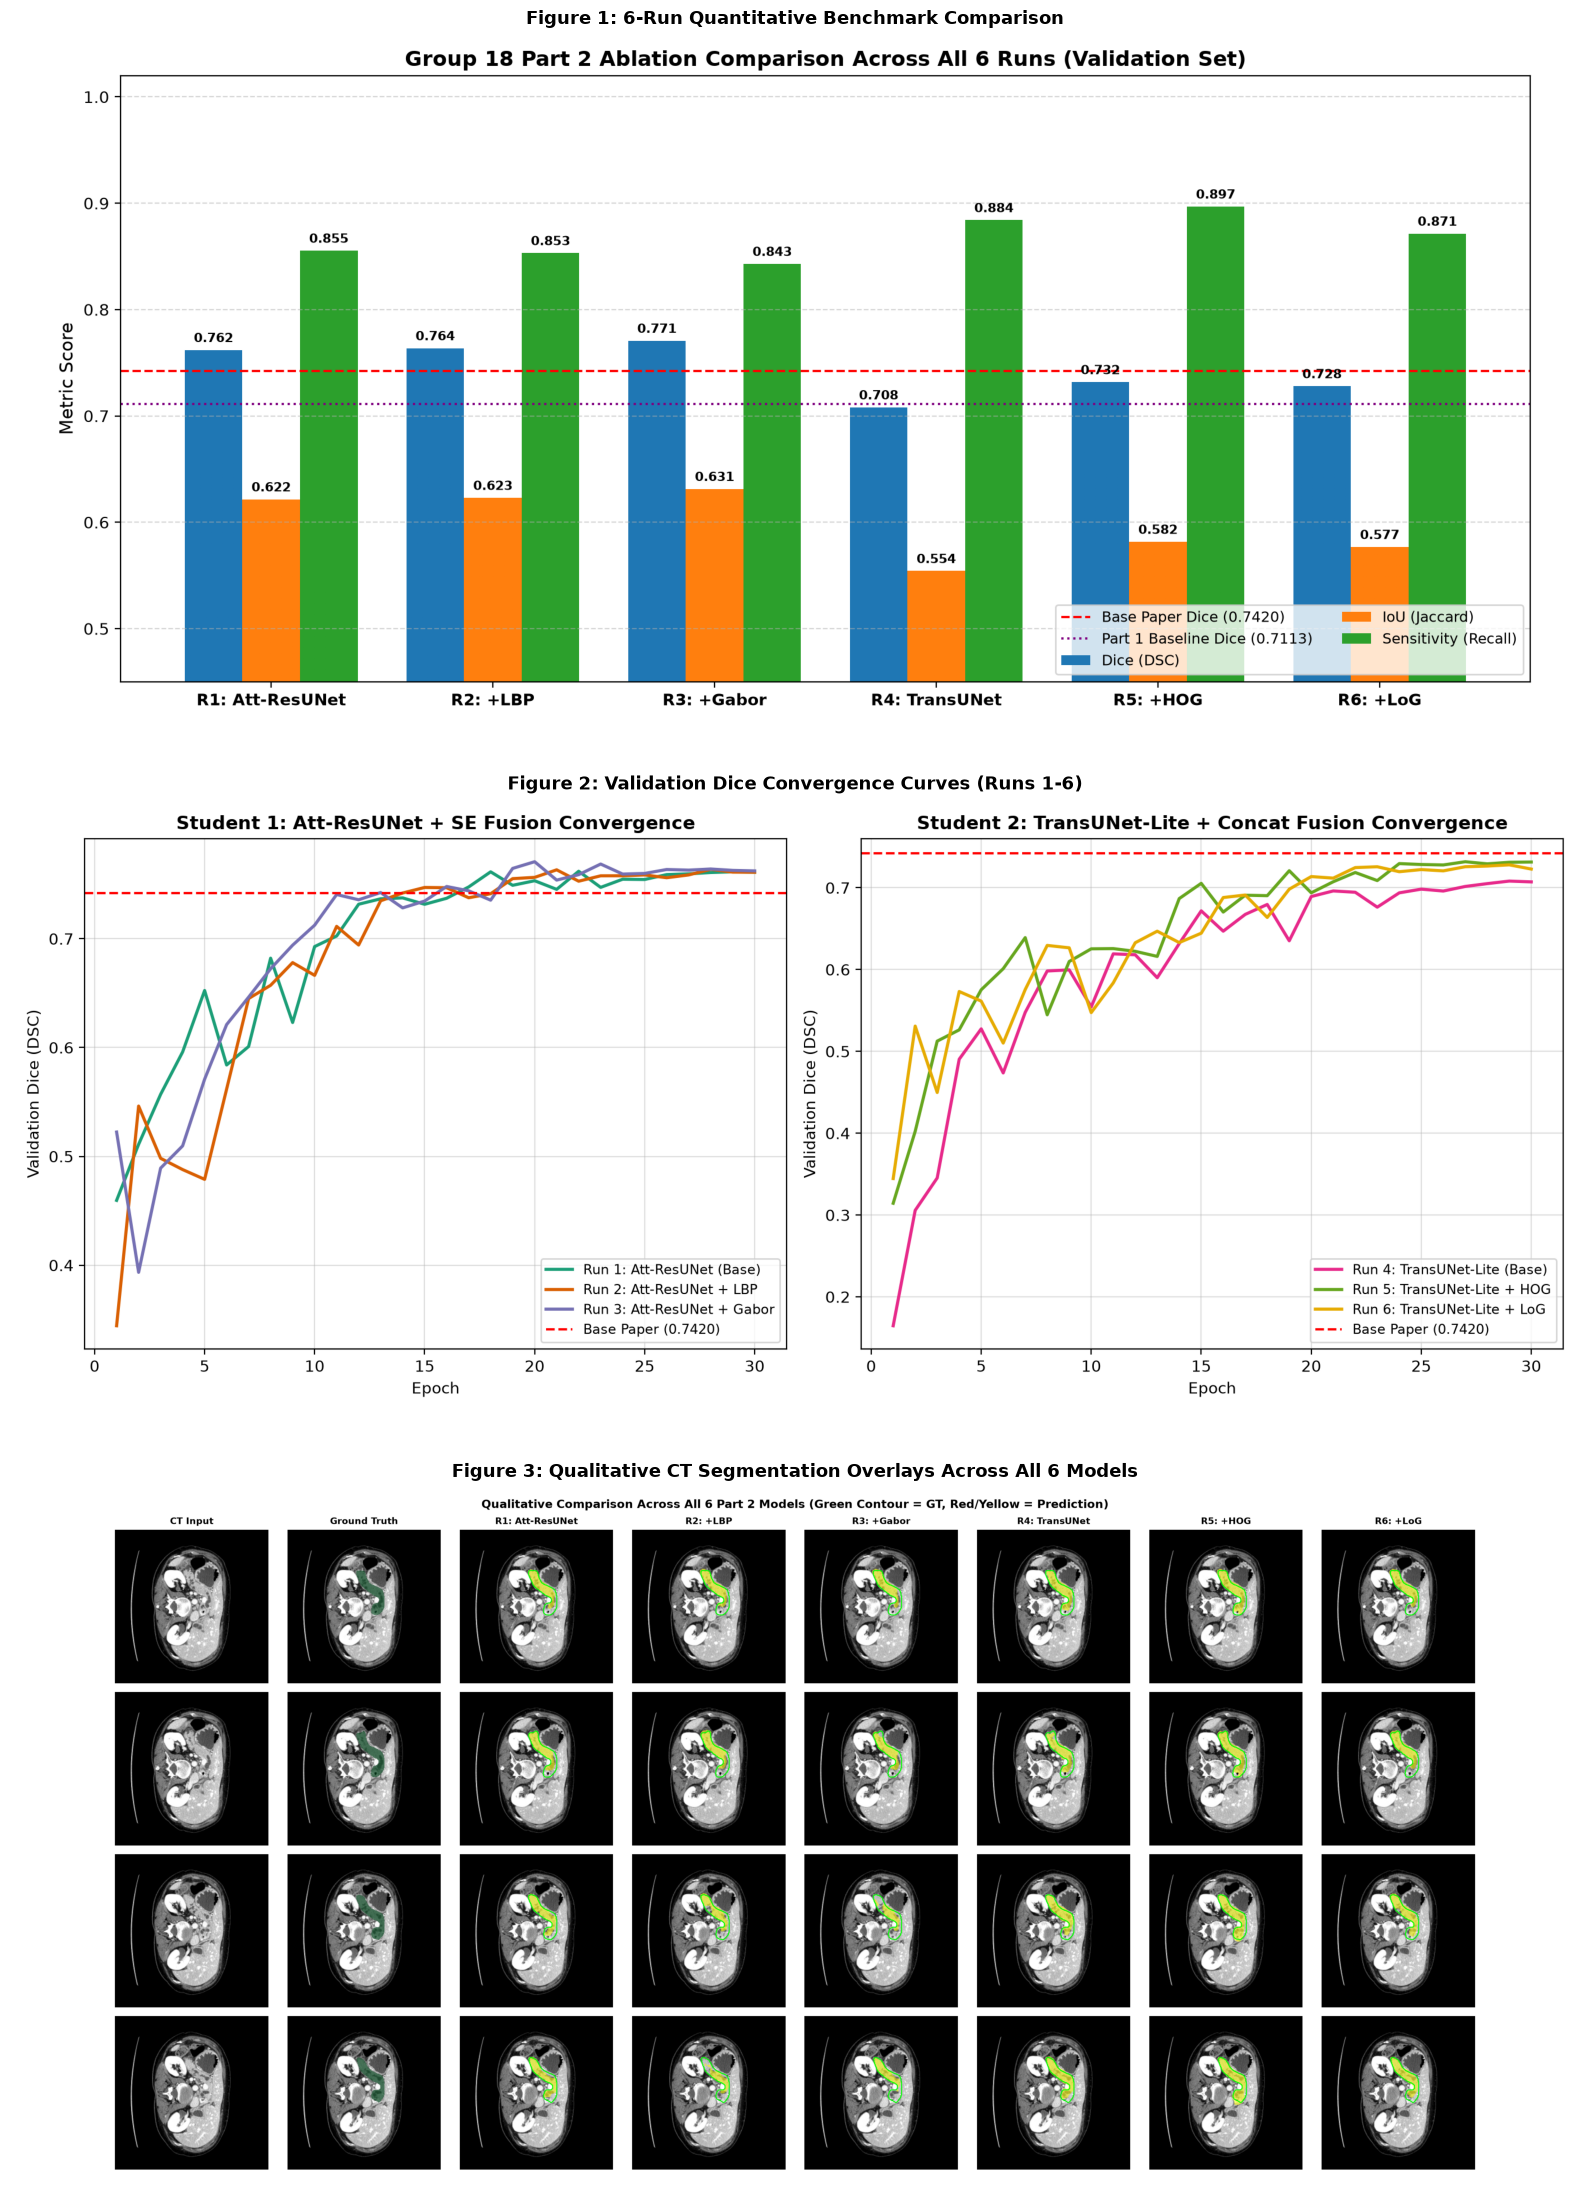

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 1, figsize=(16, 22))
imgs = [
    ('../results/part2/part2_ablation_bar_comparison.png', 'Figure 1: 6-Run Quantitative Benchmark Comparison'),
    ('../results/part2/part2_all_runs_convergence.png', 'Figure 2: Validation Dice Convergence Curves (Runs 1-6)'),
    ('../results/part2/part2_qualitative_overlays.png', 'Figure 3: Qualitative CT Segmentation Overlays Across All 6 Models')
]
for ax, (path, title) in zip(axes, imgs):
    ax.imshow(Image.open(path))
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()